In [25]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd
# 修改为自己的学号
STUDENT_ID = 20244081101
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]\t{STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")


[Conda 环境] pyexp
[学号]	20244081101
[机器指纹] 3cf3fba9863bfd88
[RUN_ID] 20244081101-3cf3fba9863bfd88


## 实验1：NumPy 数组、数据类型与索引

NumPy 数组在创建时就固定成同一种数据类型，并按连续内存存放。Python 列表里每个位置只是一个对象引用，同一个列表可以同时放下整数、字符串和别的对象。因此数组能按 dtype 做整块运算，列表则要逐个处理元素。


In [26]:
integer_array = np.array([1, 2, 3])
float_array = np.array([1.0, 2.5, 3.5])
bool_array = np.array([True, False, True])

for name, array in (("整数", integer_array), ("浮点数", float_array), ("布尔值", bool_array)):
    print(name, array)
    print("  dtype =", array.dtype)
    print("  shape =", array.shape)
    print("  ndim  =", array.ndim)


整数 [1 2 3]
  dtype = int64
  shape = (3,)
  ndim  = 1
浮点数 [1.  2.5 3.5]
  dtype = float64
  shape = (3,)
  ndim  = 1
布尔值 [ True False  True]
  dtype = bool
  shape = (3,)
  ndim  = 1


In [27]:
base = np.arange(12)
matrix = base.reshape(3, 4)
cube = base.reshape(2, 3, 2)
print("一维:", base, "元素个数", base.size)
print("形状 (3, 4):")
print(matrix)
print("形状 (2, 3, 2):")
print(cube)

try:
    base.reshape(5, 3)
except ValueError as exc:
    print("reshape(5, 3) 失败:", exc)


一维: [ 0  1  2  3  4  5  6  7  8  9 10 11] 元素个数 12
形状 (3, 4):
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
形状 (2, 3, 2):
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
reshape(5, 3) 失败: cannot reshape array of size 12 into shape (5,3)


`reshape` 不会增加或丢掉元素，所以新形状各维的乘积必须等于原来的元素总数。`12 = 3 × 4 = 2 × 3 × 2`，这两个形状都合法。`5 × 3 = 15`，和 12 对不上，因此会报错。


In [28]:
print(matrix)
print("第 2 行:", matrix[1], "形状", matrix[1].shape)
print("第 1 至第 3 列:")
print(matrix[:, 0:3], "形状", matrix[:, 0:3].shape)
greater = matrix[matrix > 6]
print("大于 6:", greater, "形状", greater.shape)


[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
第 2 行: [4 5 6 7] 形状 (4,)
第 1 至第 3 列:
[[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] 形状 (3, 3)
大于 6: [ 7  8  9 10 11] 形状 (5,)


这里按日常计数：第 2 行是下标 1，第 1 至第 3 列是下标 0、1、2。布尔索引 `matrix > 6` 把满足条件的元素收成一维数组，所以形状从 `(3, 4)` 变成 `(5,)`。


In [29]:
values = np.arange(10)
outside = values[(values < 2) | (values > 7)]
inside = values[(values > 3) & (values < 7)]
outside_fn = values[np.logical_or(values < 2, values > 7)]
inside_fn = values[np.logical_and(values > 3, values < 7)]
print("小于 2 或大于 7:", outside, outside_fn)
print("大于 3 且小于 7:", inside, inside_fn)


小于 2 或大于 7: [0 1 8 9] [0 1 8 9]
大于 3 且小于 7: [4 5 6] [4 5 6]


多个比较条件不能写成 `values < 2 or values > 7`，因为 `or` 不能逐元素判断。要把每个比较用括号括起来，再用 `|`、`&`，或者调用 `np.logical_or()`、`np.logical_and()`。


In [30]:
left = np.array([[1, 2], [3, 4]])
right = np.array([[5, 6], [7, 8]])
print("逐元素 *:")
print(left * right)
print("np.multiply:")
print(np.multiply(left, right))
print("矩阵乘法 @:")
print(left @ right)
print("np.matmul:")
print(np.matmul(left, right))


逐元素 *:
[[ 5 12]
 [21 32]]
np.multiply:
[[ 5 12]
 [21 32]]
矩阵乘法 @:
[[19 22]
 [43 50]]
np.matmul:
[[19 22]
 [43 50]]


`*` 和 `np.multiply()` 是同一件事：对应位置相乘，`(1, 2)` 和 `(5, 6)` 得到 `(5, 12)`。`@` 和 `np.matmul()` 是矩阵乘法：结果的第 i 行第 j 列，是左矩阵第 i 行与右矩阵第 j 列的内积。两种运算的形状要求和数值都不一样。


## 实验2：随机抽样、统计与缺失值

下面的随机结果都来自固定种子 `42`，重复运行会得到同一批数。


In [31]:
SEED = 42
rng = np.random.default_rng(SEED)
scores = rng.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)
print("样本数:", scores.size)
print("最小值:", scores.min())
print("最大值:", scores.max())
print("均值:", scores.mean())
print("标准差:", scores.std())
print("极差:", scores.max() - scores.min())


样本数: 1000
最小值: 33.51587174785217
最大值: 100.0
均值: 69.70929595324685
标准差: 9.881580939490172
极差: 66.48412825214783


In [32]:
population = np.arange(1, 11)
uniform_sample = rng.choice(population, size=5, replace=False)
weights = population / population.sum()
weighted_sample = rng.choice(population, size=5, replace=False, p=weights)
print("均匀、不放回:", uniform_sample)
print("权重:", weights)
print("按数值大小加权、不放回:", weighted_sample)


均匀、不放回: [7 2 9 5 4]
权重: [0.01818182 0.03636364 0.05454545 0.07272727 0.09090909 0.10909091
 0.12727273 0.14545455 0.16363636 0.18181818]
按数值大小加权、不放回: [3 9 2 6 5]


两种抽样都设置 `replace=False`，所以 5 个整数不会重复。均匀抽样里每个整数机会相同。加权抽样把概率设成整数本身占总和的比例，因此 10 比 1 更容易被抽到。


In [33]:
original = np.arange(1, 6)
print("permutation 之前:", original)
permuted = rng.permutation(original)
print("permutation 的结果:", permuted)
print("permutation 之后的原数组:", original)

shuffled = original.copy()
print("shuffle 之前:", shuffled)
rng.shuffle(shuffled)
print("shuffle 之后:", shuffled)


permutation 之前: [1 2 3 4 5]
permutation 的结果: [1 2 3 5 4]
permutation 之后的原数组: [1 2 3 4 5]
shuffle 之前: [1 2 3 4 5]
shuffle 之后: [2 4 3 5 1]


`permutation` 返回一个新的排列，原来的数组不动。`shuffle` 没有返回值，它直接改掉传入的数组。上面用副本做原地打乱，避免把后面还要用的数组弄乱。


In [34]:
scores_with_nan = scores.astype(float).copy()
scores_with_nan[[9, 19, 29]] = np.nan
print("普通均值:", np.mean(scores_with_nan))
print("忽略缺失值的均值:", np.nanmean(scores_with_nan))
print("缺失值个数:", np.isnan(scores_with_nan).sum())


普通均值: nan
忽略缺失值的均值: 69.71315691233939
缺失值个数: 3


第 10、20、30 个成绩按从 1 开始计数，对应下标 9、19、29。`np.nan` 参与加法后，结果仍是 `nan`，所以 `np.mean` 会得到 `nan`。`np.nanmean` 先跳过缺失值，再计算其余成绩的均值。


In [35]:
score_table = pd.DataFrame({
    "序号": np.arange(1, scores_with_nan.size + 1),
    "成绩": scores_with_nan,
})
print(type(score_table))
print(score_table.head())
print("缺失行:")
print(score_table.loc[score_table["成绩"].isna()])


<class 'pandas.DataFrame'>
   序号         成绩
0   1  73.047171
1   2  59.600159
2   3  77.504512
3   4  79.405647
4   5  50.489648
缺失行:
    序号  成绩
9   10 NaN
19  20 NaN
29  30 NaN


## 实验3：SciPy 数值计算与 Matplotlib 可视化

线性方程组是 `3x + y = 9` 和 `x + 2y = 8`。写成矩阵就是 `A @ [x, y] = b`。


In [36]:
equation_matrix = np.array([[3, 1], [1, 2]], dtype=float)
equation_rhs = np.array([9, 8], dtype=float)
solution = scipy.linalg.solve(equation_matrix, equation_rhs)
print("解 [x, y] =", solution)
print("代回左边:", equation_matrix @ solution)
print("与右边一致:", np.allclose(equation_matrix @ solution, equation_rhs))


解 [x, y] = [2. 3.]
代回左边: [9. 8.]
与右边一致: True


In [37]:
def quadratic_gap(x):
    return np.square(x) - 2


positive = scipy.optimize.root(quadratic_gap, 1.0)
negative = scipy.optimize.root(quadratic_gap, -1.0)
for name, result in (("正根", positive), ("负根", negative)):
    print(name, "成功:", result.success, "x =", result.x, "函数值 =", quadratic_gap(result.x))


正根 成功: True x = [1.41421356] 函数值 = [-8.8817842e-16]
负根 成功: True x = [-1.41421356] 函数值 = [-8.8817842e-16]


`x² - 2 = 0` 的根是正负根号 2。正根从 1 开始找，负根从 -1 开始找。两边都成功，代入后的函数值已经接近 0。


In [38]:
def parabola(x):
    return x[0] ** 2 + x[0] + 2


minimum = scipy.optimize.minimize(parabola, x0=np.array([0.0]))
analytic_x = -0.5
analytic_value = analytic_x ** 2 + analytic_x + 2
print("是否成功:", minimum.success)
print("数值极小点:", minimum.x[0], "函数值:", minimum.fun)
print("解析极小点:", analytic_x, "函数值:", analytic_value)
print("位置接近:", np.isclose(minimum.x[0], analytic_x))
print("函数值接近:", np.isclose(minimum.fun, analytic_value))


是否成功: True
数值极小点: -0.5000000064345924 函数值: 1.75
解析极小点: -0.5 函数值: 1.75
位置接近: True
函数值接近: True


`f(x) = x² + x + 2` 的导数是 `2x + 1`，令导数为 0 得到 `x = -1/2`，函数值是 `1.75`。数值优化的结果和这个解析解一致。


In [39]:
test_rng = np.random.default_rng(SEED)
group_zero = test_rng.normal(loc=0, scale=1, size=100)
group_one = test_rng.normal(loc=1, scale=1, size=100)
ttest = scipy.stats.ttest_ind(group_zero, group_one)
alpha = 0.05
print("t 统计量:", ttest.statistic)
print("p 值:", ttest.pvalue)
print("显著性水平:", alpha)
if ttest.pvalue < alpha:
    print("p 值小于 0.05，拒绝两组均值相等的原假设。")
else:
    print("p 值不小于 0.05，不能拒绝两组均值相等的原假设。")


t 统计量: -8.316637727945347
p 值: 1.441895340492072e-14
显著性水平: 0.05
p 值小于 0.05，拒绝两组均值相等的原假设。


两组样本分别来自均值 0 和均值 1 的标准正态分布，独立、同方差。样本量各 100 个时，均值相差一个标准差，t 检验会给出很小的 p 值，因此在 0.05 水平下认为两组均值不同。


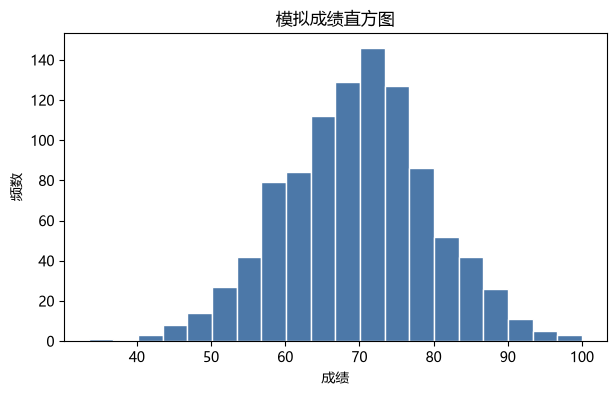

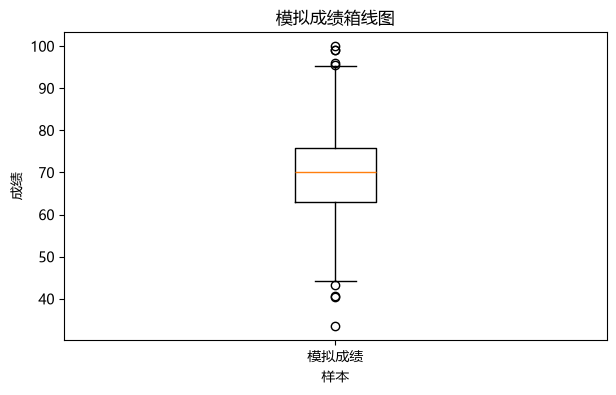

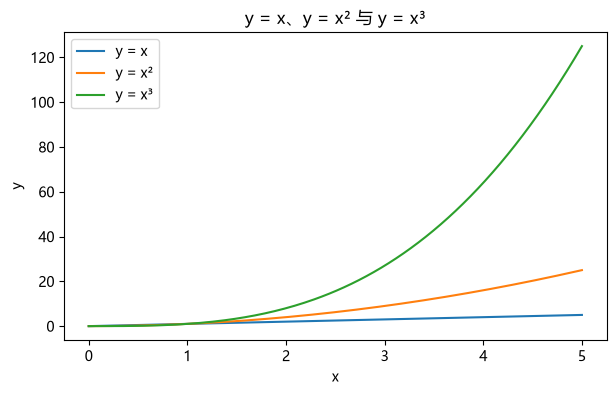

In [40]:
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

valid_scores = scores_with_nan[~np.isnan(scores_with_nan)]

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(valid_scores, bins=20, color="#4C78A8", edgecolor="white")
ax.set_title("模拟成绩直方图")
ax.set_xlabel("成绩")
ax.set_ylabel("频数")
display(fig)
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(valid_scores)
ax.set_xticks([1])
ax.set_xticklabels(["模拟成绩"])
ax.set_title("模拟成绩箱线图")
ax.set_xlabel("样本")
ax.set_ylabel("成绩")
display(fig)
plt.close(fig)

x = np.linspace(0, 5, 200)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, x, label="y = x")
ax.plot(x, x ** 2, label="y = x²")
ax.plot(x, x ** 3, label="y = x³")
ax.set_title("y = x、y = x² 与 y = x³")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
display(fig)
plt.close(fig)


直方图和箱线图只用实验 2 里去掉缺失值之后的成绩。三条曲线画在同一张图上，范围是 `0 ≤ x ≤ 5`。图像直接显示在笔记本里，不另存文件。


## 实验4：pandas Series、DataFrame 与内存中的 CSV 读写

成绩表的行索引用姓名。`Total` 是三科总分，`Average` 是三科平均分。


In [41]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
subjects = ["Math", "English", "Python"]
grades = pd.DataFrame(records).set_index("Name")
grades["Total"] = grades[subjects].sum(axis=1)
grades["Average"] = grades[subjects].mean(axis=1)

print("行索引:", grades.index.tolist())
print("列名:", grades.columns.tolist())
print("Average 的类型:", type(grades["Average"]))
print(grades.head(3))
print(grades.describe())


行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']
Average 的类型: <class 'pandas.Series'>
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [42]:
print("loc 读取 Carol:")
print(grades.loc["Carol"])
print("iloc 读取 Carol:")
print(grades.iloc[2])
print("平均分不低于 80:")
print(grades.loc[grades["Average"] >= 80])


loc 读取 Carol:
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
iloc 读取 Carol:
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
平均分不低于 80:
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [43]:
print("列均值 axis=0:")
print(grades[subjects].mean(axis=0))
print("行均值 axis=1:")
print(grades[subjects].mean(axis=1))


列均值 axis=0:
Math       79.833333
English    80.833333
Python     83.666667
dtype: float64
行均值 axis=1:
Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


`axis=0` 沿着行的方向压缩，得到每一科的平均分。`axis=1` 沿着列的方向压缩，得到每名学生三科的平均分，结果和 `Average` 列相同。


In [44]:
highest = grades[subjects].apply(max, axis=1)
print("每人最高分:")
print(highest)
print("每科的最小值、均值、最大值:")
print(grades[subjects].agg(["min", "mean", "max"]))
print("Python 排名（分数高的名次靠前）:")
print(grades["Python"].rank(ascending=False, method="min"))


每人最高分:
Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
dtype: int64
每科的最小值、均值、最大值:
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000
Python 排名（分数高的名次靠前）:
Name
Alice    1.0
Bob      5.0
Carol    2.0
David    6.0
Eva      3.0
Frank    4.0
Name: Python, dtype: float64


In [45]:
print("各组人数:")
print(grades.groupby("Group").size())
print("各组三科平均分:")
print(grades.groupby("Group")[subjects].mean())
grades["GroupPythonMean"] = grades.groupby("Group")["Python"].transform("mean")
print(grades[["Group", "Python", "GroupPythonMean"]])


各组人数:
Group
A    3
B    3
dtype: int64
各组三科平均分:
            Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333
      Group  Python  GroupPythonMean
Name                                
Alice     A      95        87.000000
Bob       A      80        87.000000
Carol     B      89        80.333333
David     B      70        80.333333
Eva       A      86        87.000000
Frank     B      82        80.333333


`transform('mean')` 先算出每组的 Python 平均分，再按原表的行数填回去。所以同组学生看到的组平均分相同，行数也不变。


In [46]:
kept = grades.groupby("Group").filter(lambda group: group["Python"].mean() >= 80)
print("保留的组:", kept["Group"].unique().tolist())
print(kept[["Group", "Python", "GroupPythonMean"]])


保留的组: ['A', 'B']
      Group  Python  GroupPythonMean
Name                                
Alice     A      95        87.000000
Bob       A      80        87.000000
Carol     B      89        80.333333
David     B      70        80.333333
Eva       A      86        87.000000
Frank     B      82        80.333333


In [47]:
covariance = grades[subjects].cov()
correlation = grades[subjects].corr()
print("协方差矩阵:")
print(covariance)
print("皮尔森相关系数矩阵:")
print(correlation)
math_english_cov = covariance.loc["Math", "English"]
math_english_corr = correlation.loc["Math", "English"]
print("Math 与 English 的协方差:", math_english_cov)
print("Math 与 English 的相关系数:", math_english_corr)


协方差矩阵:
              Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667
皮尔森相关系数矩阵:
             Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000
Math 与 English 的协方差: 62.56666666666668
Math 与 English 的相关系数: 0.6535293080615485


协方差为正，表示两科成绩倾向于一起高于或一起低于各自的平均分。相关系数把协方差标准化到 -1 和 1 之间，绝对值越接近 1，线性关系越强；接近 0 则几乎没有线性关系。Math 和 English 的协方差为正，相关系数也是正的，说明这两科是同向变化的。


In [48]:
import io

buffer = io.StringIO()
score_table.to_csv(buffer, index=False)
buffer.seek(0)
loaded_scores = pd.read_csv(buffer)
print(loaded_scores.head())
print("读回后的行数:", len(loaded_scores))
print("读回后的缺失值个数:", int(loaded_scores["成绩"].isna().sum()))


   序号         成绩
0   1  73.047171
1   2  59.600159
2   3  77.504512
3   4  79.405647
4   5  50.489648
读回后的行数: 1000
读回后的缺失值个数: 3
